# Đề tài 14: Phát hiện tin giả COVID-19 (Constraint@AAAI2021)
**Nhánh baseline (TF-IDF + SVM) và nhánh zero-shot** — bài toán · dataset · EDA · tiền xử lý · chẩn đoán overfit theo C · kiểm tra rò rỉ · phân tích lỗi · hướng khắc phục · zero-shot

Chạy từng cell từ trên xuống (có thể bỏ qua cell zero-shot nếu chưa cần). Chọn `Runtime > Change runtime type > T4 GPU` cho phần zero-shot.

## 0. Nạp dữ liệu
Chạy cell dưới, khi hiện nút **Choose Files** thì chọn cùng lúc `train.csv`, `val.csv`, `test.csv` (hoặc kéo 3 file vào thư mục `/content`).

In [ ]:
import os, re, html, time, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42; random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
COL = {"fake": "#d9534f", "real": "#5cb85c"}
pd.set_option("display.max_colwidth", 200)

if not all(os.path.exists(f) for f in ["train.csv", "val.csv", "test.csv"]):
    from google.colab import files
    files.upload()
train, val, test = pd.read_csv("train.csv"), pd.read_csv("val.csv"), pd.read_csv("test.csv")
for n, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{n:5s}: {len(d):5d} mẫu | cột: {list(d.columns)}")

Saving test.csv to test.csv
Saving train.csv to train.csv
Saving val.csv to val.csv
train:  6420 mẫu | cột: ['id', 'tweet', 'label']
val  :  2140 mẫu | cột: ['id', 'tweet', 'label']
test :  2140 mẫu | cột: ['id', 'tweet', 'label']


## 1. Bài toán & dataset
- **Bài toán:** phân loại nhị phân một bài đăng tiếng Anh về COVID-19 là **real** (thông tin thật) hay **fake** (tin giả).
- **Dataset:** 10.700 bài (Patwa et al., 2021), chia sẵn train/val/test ≈ 60/20/20. Nhãn real lấy từ nguồn chính thống, nhãn fake lấy từ các bài đã bị kiểm chứng là sai.
- **Vai trò 3 tập:** train để học · val để chẩn đoán overfit và chọn tham số · test chỉ chấm một lần ở cuối.

## 2. Khảo sát dữ liệu (EDA)

label,fake,real,fake_%
split,,,
train,3060,3360,47.7
val,1020,1120,47.7
test,1020,1120,47.7


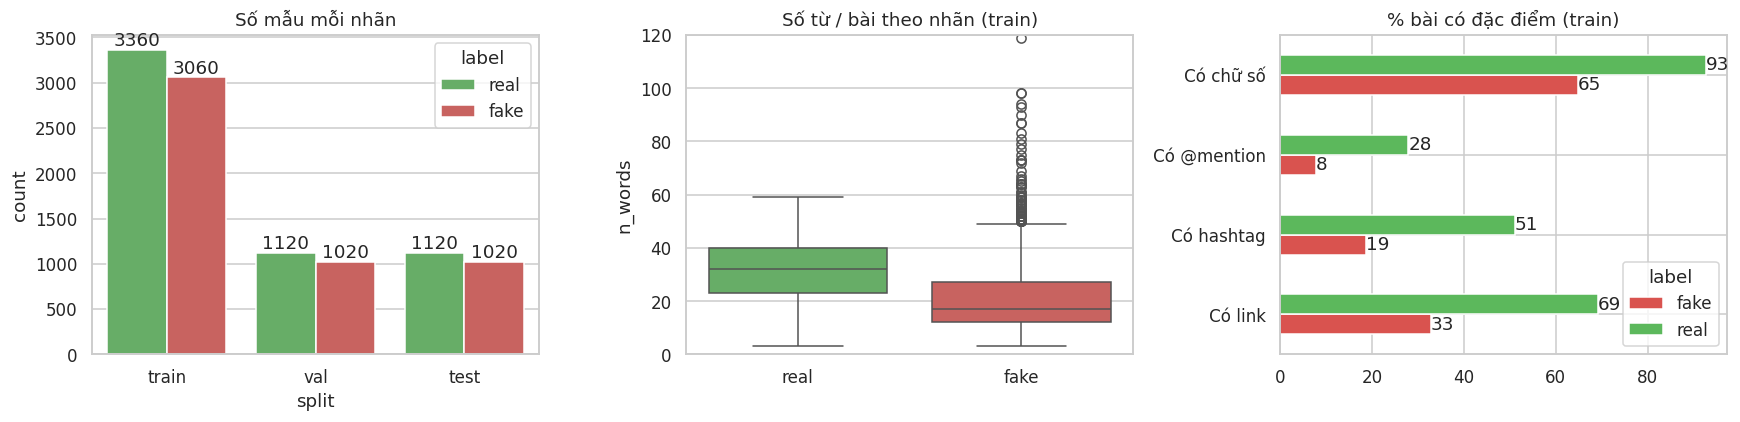

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
fake,3060.0,21.9,33.0,3.0,12.0,17.0,27.0,1456.0
real,3360.0,31.7,10.8,3.0,23.0,32.0,40.0,59.0


In [ ]:
def add_feats(d):
    d = d.copy()
    d["n_words"]  = d.tweet.str.split().str.len()
    d["has_url"]  = d.tweet.str.contains(r"https?://", regex=True)
    d["has_hash"] = d.tweet.str.contains("#")
    d["has_ment"] = d.tweet.str.contains("@")
    d["has_digit"]= d.tweet.str.contains(r"\d", regex=True)
    return d
tr = add_feats(train)
all_df = pd.concat([add_feats(train).assign(split="train"), add_feats(val).assign(split="val"), add_feats(test).assign(split="test")])
cnt = all_df.groupby(["split", "label"]).size().unstack().loc[["train", "val", "test"]]
cnt["fake_%"] = (cnt["fake"] / (cnt["fake"] + cnt["real"]) * 100).round(1); display(cnt)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=all_df, x="split", hue="label", order=["train", "val", "test"], palette=COL, ax=ax[0])
ax[0].set_title("Số mẫu mỗi nhãn"); [ax[0].bar_label(c) for c in ax[0].containers]
sns.boxplot(data=tr, x="label", y="n_words", palette=COL, ax=ax[1]); ax[1].set_ylim(0, 120)
ax[1].set_title("Số từ / bài theo nhãn (train)"); ax[1].set_xlabel("")
rate = (tr.groupby("label")[["has_url", "has_hash", "has_ment", "has_digit"]].mean().T * 100)
rate.index = ["Có link", "Có hashtag", "Có @mention", "Có chữ số"]
rate.plot(kind="barh", color=COL, ax=ax[2]); ax[2].set_title("% bài có đặc điểm (train)")
[ax[2].bar_label(c, fmt="%.0f") for c in ax[2].containers]
plt.tight_layout(); plt.show()
display(tr.groupby("label")["n_words"].describe().round(1))

**Nhận xét:** dữ liệu **cân bằng** (≈ 52% real / 48% fake ở cả 3 tập). Real có độ dài đều như tweet, fake ngắn hơn nhưng có vài bài rất dài (ngoại lai). Real có nhiều link, hashtag, @, chữ số hơn: đây có thể là "đường tắt" mô hình lợi dụng, sẽ kiểm tra ở mục 5.

## 3. Tiền xử lý
| Nhóm | Phương pháp |
|---|---|
| Làm sạch văn bản | giải mã HTML, link → `urltoken`, `@tên` → `usertoken`, bỏ dấu `#`, gộp khoảng trắng |
| Chuẩn hoá | chữ thường (lowercasing) |
| Tokenization | regex mặc định của `TfidfVectorizer` |
| N-gram | unigram + bigram |
| Lọc từ hiếm | `min_df=2` |
| Stop-word | không loại bỏ (*not, no* làm đảo nghĩa câu) |
| Stemming / Lemmatization | không dùng |
| Biểu diễn vector | Bag-of-Words có trọng số **TF-IDF** (`sublinear_tf=True`) |

In [ ]:
URL_RE, MENTION_RE, HASHTAG_RE = re.compile(r"https?://\S+"), re.compile(r"@\w+"), re.compile(r"#(\w+)")
def preprocess(s):
    s = html.unescape(s)                  # &amp; → &
    s = URL_RE.sub(" urltoken ", s)       # link → urltoken
    s = MENTION_RE.sub(" usertoken ", s)  # @tên → usertoken
    s = HASHTAG_RE.sub(r" \1 ", s)        # bỏ dấu #
    return re.sub(r"\s+", " ", s).strip().lower()
for d in (train, val, test): d["text"] = d.tweet.map(preprocess)    # cột "text" = đã xử lý
ex = train[train.tweet.str.contains("https?://", regex=True) & train.tweet.str.contains("@")].iloc[0]
print("GỐC:", ex.tweet, "\nSAU :", ex.text)

GỐC: #IndiaFightsCorona: We have 1524 #COVID testing laboratories in India and as on 25th August 2020 36827520 tests have been done : @ProfBhargava DG @ICMRDELHI #StaySafe #IndiaWillWin https://t.co/Yh3ZxknnhZ 
SAU : indiafightscorona : we have 1524 covid testing laboratories in india and as on 25th august 2020 36827520 tests have been done : usertoken dg usertoken staysafe indiawillwin urltoken


## 4. Baseline A: TF-IDF + SVM
**TF-IDF** biến mỗi bài thành vector: từ xuất hiện nhiều trong bài nhưng hiếm trong toàn tập thì trọng số cao. **SVM tuyến tính** tìm ranh giới chia hai lớp với lề lớn nhất. `TfidfVectorizer` chỉ `fit` trên train để tránh rò rỉ.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(train.text)     # fit CHỈ trên train
Xva, Xte = vec.transform(val.text), vec.transform(test.text)
print("Số đặc trưng TF-IDF:", Xtr.shape[1])
f1m = lambda y, p: f1_score(y, p, average="macro")

Số đặc trưng TF-IDF: 25547


### 4.1 Chẩn đoán overfit để chọn tham số `C`
`C` là mức "nghiêm khắc" khi SVM học: `C` nhỏ → mô hình đơn giản, học chưa đủ (**underfit**); `C` lớn → cố khớp từng bài train, dễ **học vẹt (overfit)**. Ta thử nhiều giá trị `C`, vẽ F1 trên **train** và trên **val** cạnh nhau, rồi chọn `C` cho val cao nhất. Không chọn theo train vì train luôn khuyến khích `C` lớn.

,F1 train,F1 val,chênh lệch
C,,,
0.01,0.9229,0.9005,0.0224
0.03,0.9412,0.9151,0.0260
0.10,0.9697,0.9283,0.0415
0.30,0.9934,0.9428,0.0507
1.00,1.0000,0.9465,0.0535
3.00,1.0000,0.9479,0.0521
10.00,1.0000,0.9470,0.0530
100.00,1.0000,0.9447,0.0553


C cho F1 val cao nhất: 3


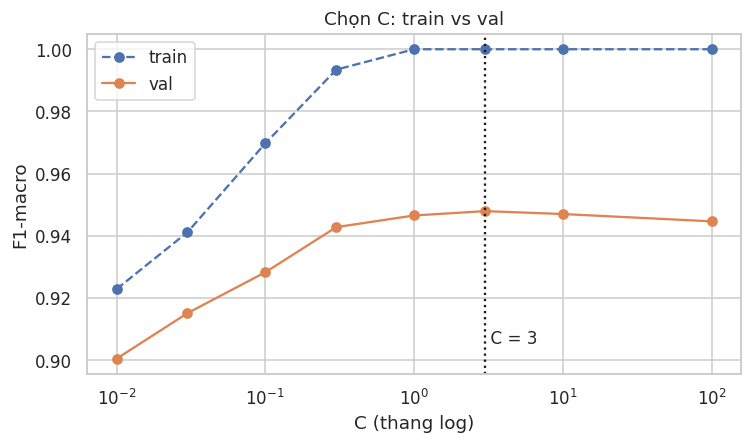

In [ ]:
Cs = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]
f_tr, f_va = [], []
for C in Cs:
    m = LinearSVC(C=C).fit(Xtr, train.label)
    f_tr.append(f1m(train.label, m.predict(Xtr))); f_va.append(f1m(val.label, m.predict(Xva)))
vcurve = pd.DataFrame({"F1 train": f_tr, "F1 val": f_va, "chênh lệch": np.array(f_tr) - np.array(f_va)}, index=pd.Index(Cs, name="C")); display(vcurve.round(4))
bestC = Cs[int(np.argmax(f_va))]
print("C cho F1 val cao nhất:", bestC)

plt.figure(figsize=(7, 4.2))
plt.plot(Cs, f_tr, "o--", label="train"); plt.plot(Cs, f_va, "o-", label="val")
plt.axvline(bestC, c="k", ls=":"); plt.text(bestC, min(f_va) + 0.005, f" C = {bestC}", fontsize=11)
plt.xscale("log"); plt.xlabel("C (thang log)"); plt.ylabel("F1-macro"); plt.title("Chọn C: train vs val"); plt.legend(); plt.tight_layout(); plt.show()

**Cách đọc:**
- **Bên trái (C nhỏ):** cả train và val đều thấp → mô hình *học chưa đủ* (underfit).
- **Giữa (điểm cao nhất của đường val):** mô hình học vừa đủ, đây là `C` ta chọn.
- **Bên phải (C lớn):** F1 train chạm 1,0 còn F1 val không tăng nữa, thậm chí giảm nhẹ → mô hình *học vẹt* (overfit): khoảng cách giữa hai đường là mức overfit.
- Vì sao dùng val để chọn: train luôn nói "`C` càng lớn càng tốt"; test phải giữ bí mật đến cuối.

,accuracy,precision_fake,recall_fake,f1_macro
tập,,,,
val,0.9481,0.9586,0.9314,0.9479
test,0.9505,0.9507,0.9451,0.9503


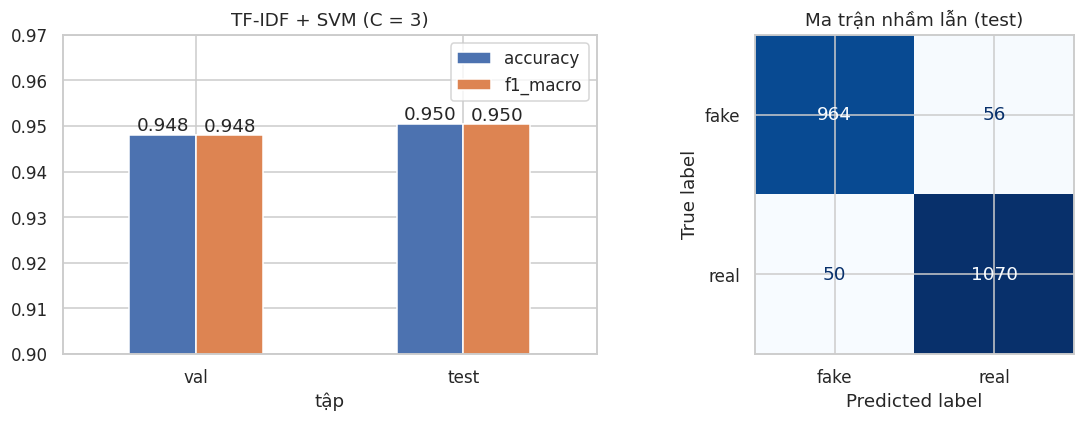

Train accuracy: 1.0 → khoảng cách so với val/test là mức overfit còn lại.


In [ ]:
# --- Mô hình cuối: LinearSVC với C đã chọn theo val
svm = LinearSVC(C=bestC).fit(Xtr, train.label)
rows = []
for split, X, y in [("val", Xva, val.label), ("test", Xte, test.label)]:
    p = svm.predict(X)
    rows.append(dict(tập=split, accuracy=accuracy_score(y, p), precision_fake=precision_score(y, p, pos_label="fake"),
                     recall_fake=recall_score(y, p, pos_label="fake"), f1_macro=f1m(y, p)))
res = pd.DataFrame(rows).set_index("tập"); display(res.round(4))
test_pred = svm.predict(Xte)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
res[["accuracy", "f1_macro"]].plot(kind="bar", rot=0, ax=ax[0]); ax[0].set_ylim(0.9, 0.97); ax[0].set_title(f"TF-IDF + SVM (C = {bestC})")
[ax[0].bar_label(c, fmt="%.3f") for c in ax[0].containers]
ConfusionMatrixDisplay(confusion_matrix(test.label, test_pred, labels=["fake", "real"]), display_labels=["fake", "real"]).plot(ax=ax[1], colorbar=False, cmap="Blues")
ax[1].set_title("Ma trận nhầm lẫn (test)"); plt.tight_layout(); plt.show()
print("Train accuracy:", round(accuracy_score(train.label, svm.predict(Xtr)), 4), "→ khoảng cách so với val/test là mức overfit còn lại.")

**Nhận xét:** nêu điểm val và test (gần nhau → không học vẹt theo val), so với train (gần 1,0 → có overfit nhẹ do số đặc trưng lớn hơn số mẫu), và loại lỗi trong ma trận nhầm lẫn (bỏ sót tin giả hay báo nhầm tin thật).

## 5. Kiểm tra rò rỉ dữ liệu
**Rò rỉ dữ liệu** là khi mô hình đã "thấy trước đề thi" lúc học nên điểm cao giả. Ta kiểm tra bằng hai cách đơn giản:
1. **So đề:** có bài nào trong tập test trùng với bài trong tập train không? (Ngoài ra ta luôn `fit` TF-IDF chỉ trên train, nên test không lọt vào lúc chuẩn bị dữ liệu.)
2. **Thêm câu ngoài dataset:** tự viết/tìm một vài câu mới, chắc chắn không nằm trong dữ liệu, rồi xem mô hình đoán thế nào. Đây là kiểm tra thực tế xem mô hình có hoạt động trên dữ liệu mới không. Lưu ý: cách này kiểm tra *khả năng khái quát*, không trực tiếp chứng minh có rò rỉ hay không, và chỉ vài câu thì quá ít để kết luận chắc (mỗi câu sai làm tỉ lệ đúng lệch 10 điểm phần trăm).

In [ ]:
# Cách 1: so đề
S_train = set(train.text)
dup = test.text.isin(S_train).values
print(f"Bài test có nội dung trùng bài trong train: {dup.sum()}/{len(test)} ({dup.mean():.1%})")
print(f"Trùng giữa train và val: {val.text.isin(S_train).sum()} bài | trùng trong chính train: {train.text.duplicated().sum()} bài")
print("F1 test khi giữ nguyên:", round(f1m(test.label, test_pred), 4), "| sau khi bỏ các bài trùng:", round(f1m(test.label[~dup], test_pred[~dup]), 4))

Bài test có nội dung trùng bài trong train: 34/2140 (1.6%)
Trùng giữa train và val: 29 bài | trùng trong chính train: 40 bài
F1 test khi giữ nguyên: 0.9503 | sau khi bỏ các bài trùng: 0.9496


In [ ]:
# Cách 2: câu ngoài dataset (bạn có thể sửa/thêm câu; nhãn nên lấy từ nguồn đáng tin: WHO/CDC cho real, bài kiểm chứng đã bác bỏ cho fake)
ext = [("WHO recommends washing your hands frequently with soap and water to reduce the risk of infection.", "real"),
       ("Wearing a mask in crowded indoor places can help reduce the spread of COVID-19.", "real"),
       ("The health ministry reported 1,250 new confirmed COVID-19 cases and 14 deaths in the last 24 hours.", "real"),
       ("Vaccines are approved only after clinical trials show they are safe and effective.", "real"),
       ("People with symptoms such as fever, cough or loss of taste or smell should get tested and isolate.", "real"),
       ("Drinking bleach or disinfectant kills the coronavirus inside your body.", "fake"),
       ("5G mobile towers spread the coronavirus, so they must be shut down immediately.", "fake"),
       ("Eating raw garlic every morning completely prevents COVID-19 infection.", "fake"),
       ("Breaking: the government is hiding a secret cure for coronavirus that works in 24 hours.", "fake"),
       ("COVID-19 vaccines contain microchips that let the government track everyone.", "fake")]
Xe = vec.transform([preprocess(t) for t, _ in ext]); pe = svm.predict(Xe); se = svm.decision_function(Xe)
extdf = pd.DataFrame({"câu": [t for t, _ in ext], "thật": [l for _, l in ext], "đoán": pe, "điểm (>0 real, <0 fake)": se.round(2)})
extdf["đúng?"] = np.where(extdf["thật"] == extdf["đoán"], "đúng", "SAI")
display(extdf)
print(f"Đúng {(extdf['thật'] == extdf['đoán']).sum()}/{len(ext)} câu ngoài dataset")

,câu,thật,đoán,"điểm (>0 real, <0 fake)",đúng?
0,WHO recommends washing your hands frequently with soap and water to reduce the risk of infection.,real,real,0.30,đúng
1,Wearing a mask in crowded indoor places can help reduce the spread of COVID-19.,real,fake,-0.04,SAI
2,"The health ministry reported 1,250 new confirmed COVID-19 cases and 14 deaths in the last 24 hours.",real,fake,-0.08,SAI
3,Vaccines are approved only after clinical trials show they are safe and effective.,real,fake,-0.20,SAI
4,"People with symptoms such as fever, cough or loss of taste or smell should get tested and isolate.",real,real,0.48,đúng
5,Drinking bleach or disinfectant kills the coronavirus inside your body.,fake,fake,-1.56,đúng
6,"5G mobile towers spread the coronavirus, so they must be shut down immediately.",fake,fake,-1.42,đúng
7,Eating raw garlic every morning completely prevents COVID-19 infection.,fake,fake,-1.84,đúng
8,Breaking: the government is hiding a secret cure for coronavirus that works in 24 hours.,fake,fake,-1.39,đúng
9,COVID-19 vaccines contain microchips that let the government track everyone.,fake,fake,-1.50,đúng


Đúng 7/10 câu ngoài dataset


**Kết luận:**
- **So đề:** chỉ một tỉ lệ rất nhỏ bài test trùng train và bỏ chúng đi điểm gần như không đổi → không có rò rỉ nghiêm trọng.
- **Câu ngoài dataset:** đọc cột `điểm`. Nếu các câu sai đều có |điểm| rất nhỏ thì mô hình đang *lưỡng lự* chứ không bị lừa. Các câu viết trơn (không link, hashtag) khác phong cách tweet trong dataset, nên nếu câu *real* hay bị đoán là fake thì đó là dấu hiệu mô hình dựa một phần vào **hình thức** (link, hashtag) như EDA đã gợi ý. Đây là hạn chế cần nêu, và chỉ 10 câu thì chỉ là kiểm tra nhanh.

## 6. Phân tích lỗi: mô hình sai ở những câu nào, vì sao?
Phân tích trên tập **val** (không dùng test để khỏi "nhìn đề"). Ba góc nhìn: (1) loại lỗi và mức tự tin, (2) nhóm bài nào dễ sai, (3) đọc từng câu sai và xem **từ nào đẩy mô hình sang quyết định sai**.

Số bài val sai: 111/2140 (5.2%)


đoán,fake,real
thật,,
fake,950,70
real,41,1079


→ Bỏ sót tin giả (fake→real): 70 | Báo nhầm (real→fake): 41


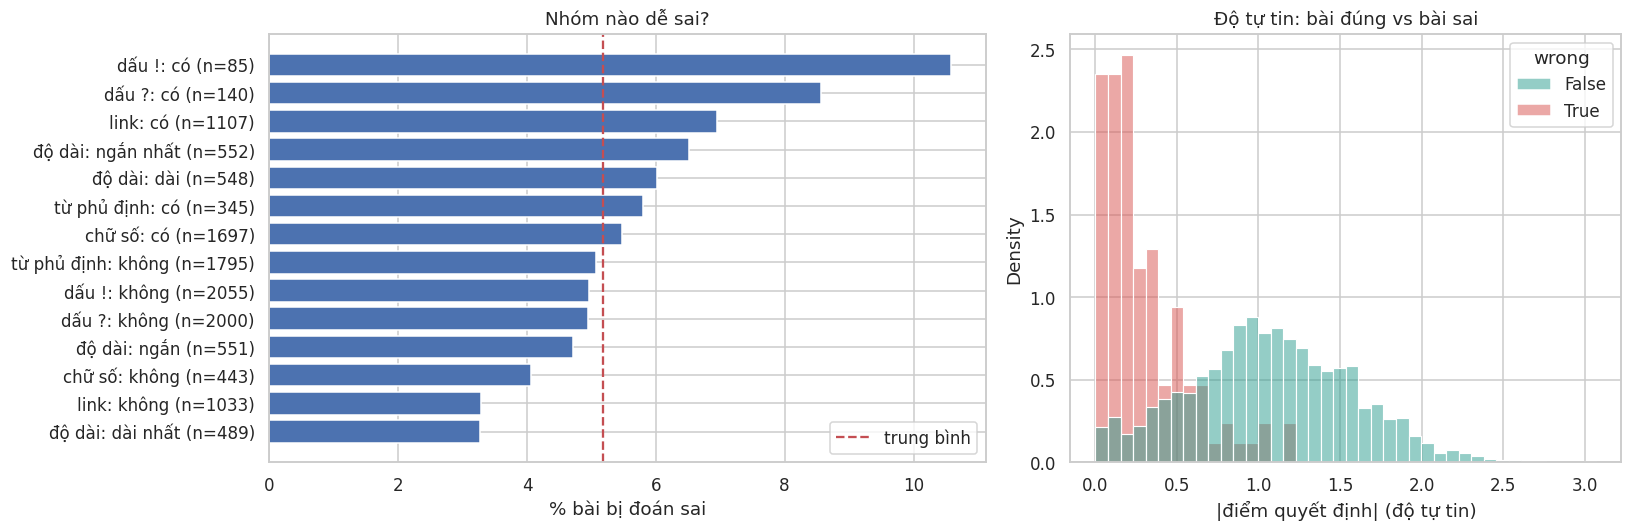

Độ tự tin trung vị: bài sai = 0.22, bài đúng = 1.06


In [ ]:
val_pred = svm.predict(Xva); score = svm.decision_function(Xva)      # score > 0 → real, < 0 → fake; |score| càng lớn càng tự tin
v = add_feats(val).assign(pred=val_pred, score=score, wrong=(val_pred != val.label.values))
v["neg"] = v.tweet.str.lower().str.contains(r"\b(?:not|no|never|without)\b|n't")
v["has_q"], v["has_excl"] = v.tweet.str.contains(r"\?"), v.tweet.str.contains("!")
print(f"Số bài val sai: {v.wrong.sum()}/{len(v)} ({v.wrong.mean():.1%})")
display(pd.crosstab(v.label, v.pred, rownames=["thật"], colnames=["đoán"]))
print("→ Bỏ sót tin giả (fake→real):", ((v.label == "fake") & (v.pred == "real")).sum(), "| Báo nhầm (real→fake):", ((v.label == "real") & (v.pred == "fake")).sum())

# (2) tỉ lệ sai theo nhóm
v["độ dài"] = pd.qcut(v.n_words, 4, labels=["ngắn nhất", "ngắn", "dài", "dài nhất"])
groups = {"độ dài: " + str(k): g for k, g in v.groupby("độ dài")}
for col, nm in [("has_url", "link"), ("has_digit", "chữ số"), ("neg", "từ phủ định"), ("has_q", "dấu ?"), ("has_excl", "dấu !")]:
    for val_, g in v.groupby(col): groups[f"{nm}: {'có' if val_ else 'không'}"] = g
gdf = pd.DataFrame([(k, g.wrong.mean() * 100, len(g)) for k, g in groups.items()], columns=["nhóm", "tỉ lệ sai %", "số bài"]).set_index("nhóm")

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.3, 1]})
g2 = gdf.sort_values("tỉ lệ sai %")
ax[0].barh([f"{i} (n={int(r['số bài'])})" for i, r in g2.iterrows()], g2["tỉ lệ sai %"], color="#4c72b0")
ax[0].axvline(v.wrong.mean() * 100, c="r", ls="--", label="trung bình"); ax[0].set_xlabel("% bài bị đoán sai"); ax[0].set_title("Nhóm nào dễ sai?"); ax[0].legend()
sns.histplot(data=v, x=v.score.abs(), hue="wrong", bins=40, stat="density", common_norm=False, ax=ax[1], palette={False: "#2a9d8f", True: "#d9534f"})
ax[1].set_xlabel("|điểm quyết định| (độ tự tin)"); ax[1].set_title("Độ tự tin: bài đúng vs bài sai")
plt.tight_layout(); plt.show()
print(f"Độ tự tin trung vị: bài sai = {v[v.wrong].score.abs().median():.2f}, bài đúng = {v[~v.wrong].score.abs().median():.2f}")

In [ ]:
# (3) Đọc từng câu sai + từ đẩy mô hình sang quyết định sai
feat = np.array(vec.get_feature_names_out())
def push_words(i, k=5):
    c = Xva[i].multiply(svm.coef_[0]).tocoo(); s = pd.Series(c.data, feat[c.col])      # trọng số > 0 nghiêng về real
    return ", ".join((s.nlargest(k) if val_pred[i] == "real" else s.nsmallest(k)).index)

def show(mask, title, k=5):
    idx = np.where(mask)[0]; idx = idx[np.argsort(-np.abs(score[idx]))][:k]
    print(f"\n=== {title} ===")
    display(pd.DataFrame({"tweet": val.tweet.values[idx], "thật": val.label.values[idx], "đoán": val_pred[idx],
                          "điểm": score[idx].round(2), "từ đẩy sang quyết định sai": [push_words(i) for i in idx]}))
w = v.wrong.values
show(w & (v.label == "fake").values, "Bỏ sót tin giả (fake -> real), SAI TỰ TIN nhất")
show(w & (v.label == "real").values, "Báo nhầm (real -> fake), SAI TỰ TIN nhất")
sat = np.where(w & (np.abs(score) < 0.15))[0]
print(f"\nSai nhưng sát ranh giới (|điểm| < 0,15): {len(sat)}/{w.sum()} bài, tức là mô hình vốn đã lưỡng lự")


=== Bỏ sót tin giả (fake → real), SAI TỰ TIN nhất ===


,tweet,thật,đoán,điểm,từ đẩy sang quyết định sai
0,.@realdonaldtrump cherry-picked one stat to prove that the US is doing better than most countries in the #COVID19 fight. Other key measures show the opposite. See the charts. https://t.co/JY6Ojd1G7Y,fake,real,1.05,"urltoken, measures, usertoken, key, the covid19"
1,RT @JNInstitute: The Judith Neilson Institute is working with @ABCFactCheck to tackle misinformation during the #COVID19 pandemic. https:…,fake,real,1.01,"usertoken, rt, rt usertoken, the covid19, covid19"
2,"Sources confirm COVID 19 Vaccine Needs at least 6 to 10m for Clinical Trials on more than 5000 But @ICMR Choosing only 1100 +ve Patients &amp; Eager to complete Before August 15,2020 means...? htt...",fake,real,0.95,"urltoken, usertoken, sources, more, patients"
3,"if we test aggressively test through RT PCR, TRUENAT,ANTIGEN tests Definitely KA cross 1.5lac COVID 19 +ve cases..Still Our @MoHFW_INDIA updating ""Invisible data's""..! At least 10m We should strug...",fake,real,0.87,"usertoken, rt, urltoken, data, we"
4,"IACC is to Autism as ""X"" is to COVID https://t.co/447cYfVImc",fake,real,0.70,"urltoken, is to, covid urltoken, to, as"



=== Báo nhầm (real → fake), SAI TỰ TIN nhất ===


,tweet,thật,đoán,điểm,từ đẩy sang quyết định sai
0,You can still fly the friendly skies without fear of COVID if airlines stay serious about safety. https://t.co/H8mGjwDl7G #coronavirus,real,fake,-1.21,"urltoken coronavirus, coronavirus, without, airlines, serious"
1,Children are not immune to the #coronavirus. https://t.co/xA8tVVMTYU,real,fake,-1.18,"coronavirus, the coronavirus, immune, children are, not"
2,#ZuckOff #TakeItFromADoctor and a video with false claims on mask wearing and #hydroxychloroquine. https://t.co/0WH13B5iqT https://t.co/04eETBikNd,real,fake,-0.84,"false, hydroxychloroquine, claims, video, hydroxychloroquine urltoken"
3,Coronavirus: Unemployment rate climbs as pandemic takes toll https://t.co/4ZSrP1FkbK,real,fake,-0.81,"coronavirus, pandemic, unemployment, toll urltoken, climbs"
4,Coronavirus: Sir Keir Starmer says second lockdown would be 'government failure - not an act of god' https://t.co/e5uyUTVlEj,real,fake,-0.69,"coronavirus, god, lockdown, government, sir"



Sai nhưng sát ranh giới (|điểm| < 0,15): 38/111 bài, tức là mô hình vốn đã lưỡng lự


**Phân tích nguyên nhân (đọc theo kết quả của bạn):**
1. **Phần lớn lỗi ở sát ranh giới:** độ tự tin trung vị của bài sai thấp hơn hẳn bài đúng → mô hình phân vân, không phải bị lừa hoàn toàn. Chỉ một ít bài sai mà rất tự tin; đó là những ca đáng đọc kỹ nhất.
2. **Bỏ sót tin giả nhiều hơn báo nhầm:** tin giả viết giọng như tin thật (trang trọng, có số liệu, có link) nên kéo mô hình về real. Cột "từ đẩy sang quyết định sai" thường là các từ/cụm của giọng văn chính thống.
3. **Nhóm dễ sai:** nhìn biểu đồ nhóm để chỉ ra nhóm nào cao hơn trung bình (thường là bài ngắn, ít ngữ cảnh; bài có dấu `!` hoặc `?`). Chú ý cỡ mẫu `n` của từng nhóm: nhóm nhỏ thì tỉ lệ dao động mạnh, đừng kết luận quá chắc.
4. **Gốc rễ:** TF-IDF chỉ *đếm từ*; nó không hiểu ngữ nghĩa (châm biếm, phủ định), không kiểm chứng sự thật, và nhãn lại gán theo nguồn nên có bài nhãn fake mà văn phong không có gì giả.

## 7. Nâng cao: hướng khắc phục
Từ phân tích lỗi, ta thử các cải tiến *nhỏ và rẻ*, đo trên **val** (không dùng test để chọn):
- **N-gram dài hơn** (1–3 từ): giữ cụm dài hơn như "not been proven".
- **Thêm 3 thống kê** (độ dài, số dấu `!`, có link): bổ sung dấu hiệu hình thức.
- **Thêm n-gram theo ký tự** (2–5 ký tự): bắt biến thể chính tả, số, tên riêng mà từ nguyên vẹn bỏ sót.
Chọn cải tiến tốt nhất theo val rồi **chấm test đúng một lần**.

,F1_val,số_lỗi_val
Gốc (từ 1–2),0.9479,111.0
N-gram từ 1–3,0.9489,109.0
+ 3 thống kê,0.9480,111.0
+ n-gram ký tự (2–5),0.9578,90.0


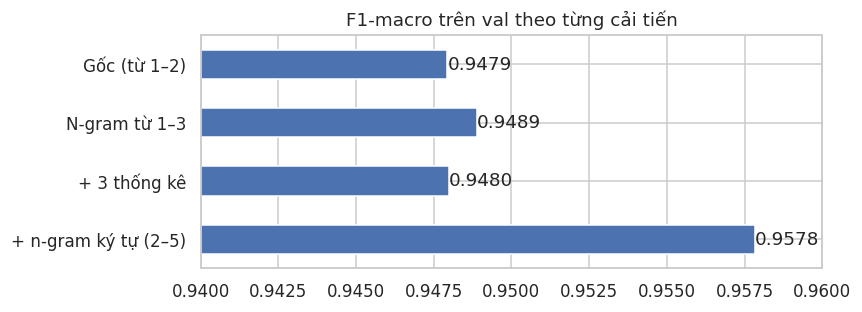

Cải tiến tốt nhất theo val: + n-gram ký tự (2–5)


,SVM gốc,SVM + n-gram ký tự (2–5)
accuracy (test),0.9505,0.9612
F1-macro (test),0.9503,0.9611
số bài sai (test),106.0000,83.0000


In [ ]:
from scipy.sparse import hstack, csr_matrix
def stats(d): return csr_matrix(np.c_[np.log1p(d.tweet.str.split().str.len()), d.tweet.str.count("!"), d.tweet.str.contains("http") * 1.0])

cv = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=150000)
Ctr = cv.fit_transform(train.text); Cva, Cte = cv.transform(val.text), cv.transform(test.text)
v3 = TfidfVectorizer(ngram_range=(1, 3), min_df=2, sublinear_tf=True)
T3tr = v3.fit_transform(train.text); T3va, T3te = v3.transform(val.text), v3.transform(test.text)

variants = {   # tên: (X train, X val, X test)
    "Gốc (từ 1–2)":           (Xtr, Xva, Xte),
    "N-gram từ 1–3":          (T3tr, T3va, T3te),
    "+ 3 thống kê":           (hstack([Xtr, stats(train)]).tocsr(), hstack([Xva, stats(val)]).tocsr(), hstack([Xte, stats(test)]).tocsr()),
    "+ n-gram ký tự (2–5)":   (hstack([Xtr, Ctr]).tocsr(), hstack([Xva, Cva]).tocsr(), hstack([Xte, Cte]).tocsr()),
}
vres = {}
for name, (A, B, _) in variants.items():
    m = LinearSVC(C=bestC).fit(A, train.label); p = m.predict(B)
    vres[name] = dict(F1_val=f1m(val.label, p), số_lỗi_val=int((p != val.label.values).sum()))
vres = pd.DataFrame(vres).T; display(vres.round(4))
ax = vres["F1_val"].plot(kind="barh", figsize=(8, 3), color="#4c72b0"); ax.set_xlim(0.94, 0.96); ax.invert_yaxis()
[ax.bar_label(c, fmt="%.4f") for c in ax.containers]; ax.set_title("F1-macro trên val theo từng cải tiến"); plt.tight_layout(); plt.show()

best_name = vres["F1_val"].idxmax(); print("Cải tiến tốt nhất theo val:", best_name)
A, B, Tt = variants[best_name]
imp = LinearSVC(C=bestC).fit(A, train.label); imp_pred = imp.predict(Tt)
cmp_ = pd.DataFrame({"SVM gốc": [accuracy_score(test.label, test_pred), f1m(test.label, test_pred), int((test_pred != test.label.values).sum())],
                     f"SVM {best_name}": [accuracy_score(test.label, imp_pred), f1m(test.label, imp_pred), int((imp_pred != test.label.values).sum())]},
                    index=["accuracy (test)", "F1-macro (test)", "số bài sai (test)"])
display(cmp_.round(4))

**Cách đọc:** so từng dòng với dòng *Gốc*. Cải tiến nào làm F1 val và số lỗi tốt hơn **đáng kể** thì giữ; nếu chênh chỉ vài phần nghìn (tương đương 1–2 bài) thì coi là không khác. Điểm test của mô hình cải tiến chỉ để xác nhận, không dùng để chọn lại.

**Hướng khắc phục dài hạn** (ngoài phạm vi baseline): (1) **fine-tune Transformer** (hiểu ngữ cảnh, phủ định, châm biếm); (2) bổ sung dữ liệu/nguồn để giảm phụ thuộc vào văn phong một nguồn; (3) kết hợp kiểm chứng ngoài (tra cứu nguồn) vì chỉ dựa vào văn bản thì không thể xác minh sự thật.

## 8. Zero-shot B: mô hình pretrained, không fine-tune (theo yêu cầu đề tài)
Dùng đúng `pipeline("zero-shot-classification")` của Hugging Face với `facebook/bart-large-mnli`, **không fine-tune**, cách đặt nhãn đơn giản và cố định (không tinh chỉnh theo kết quả). Mô hình đã học bài toán **NLI** (câu thứ hai có suy ra được từ câu thứ nhất không); pipeline ghép mỗi nhãn thành một **giả thuyết** ("This is real news." / "This is fake news."), hỏi bài đăng suy ra giả thuyết nào hơn, rồi chuẩn hoá điểm thành xác suất. Chạy trên test mất khoảng 3–6 phút với GPU T4.

In [ ]:
import torch
from transformers import pipeline
device = 0 if torch.cuda.is_available() else -1
zs = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=device,
              torch_dtype=torch.float16 if device == 0 else torch.float32)

def clean_nli(s):   # bỏ link, @tên vì vô nghĩa với mô hình ngôn ngữ
    s = MENTION_RE.sub(" ", URL_RE.sub(" ", html.unescape(s)))
    return re.sub(r"\s+", " ", s).strip() or "."

# Xem pipeline làm gì với MỘT bài
print(zs(clean_nli(val.tweet.iloc[0]), candidate_labels=["real news", "fake news"], hypothesis_template="This is {}."))

t0 = time.time()
out = zs([clean_nli(t) for t in test.tweet], candidate_labels=["real news", "fake news"], hypothesis_template="This is {}.", batch_size=32)
pf = np.array([dict(zip(o["labels"], o["scores"]))["fake news"] for o in out])    # xác suất fake
zs_pred = np.where(pf > 0.5, "fake", "real"); print(f"Xong sau {time.time()-t0:.0f}s")

zs_res = dict(accuracy=accuracy_score(test.label, zs_pred), precision_fake=precision_score(test.label, zs_pred, pos_label="fake"),
              recall_fake=recall_score(test.label, zs_pred, pos_label="fake"), f1_macro=f1m(test.label, zs_pred))
print({k: round(x, 4) for k, x in zs_res.items()})
print("AUC:", round(roc_auc_score(test.label == "fake", pf), 4), "| % bài bị đoán là fake:", f"{(zs_pred == 'fake').mean():.1%}", "(thực tế ≈ 47.7%)")

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'Chinese converting to Islam after realising that no muslim was affected by #Coronavirus #COVD19 in the country', 'labels': ['real news', 'fake news'], 'scores': [0.9298555850982666, 0.07014444470405579]}
Xong sau 19s
{'accuracy': 0.571, 'precision_fake': 0.9397, 'recall_fake': 0.1069, 'f1_macro': 0.45}
AUC: 0.735 | % bài bị đoán là fake: 5.4% (thực tế ≈ 47.7%)


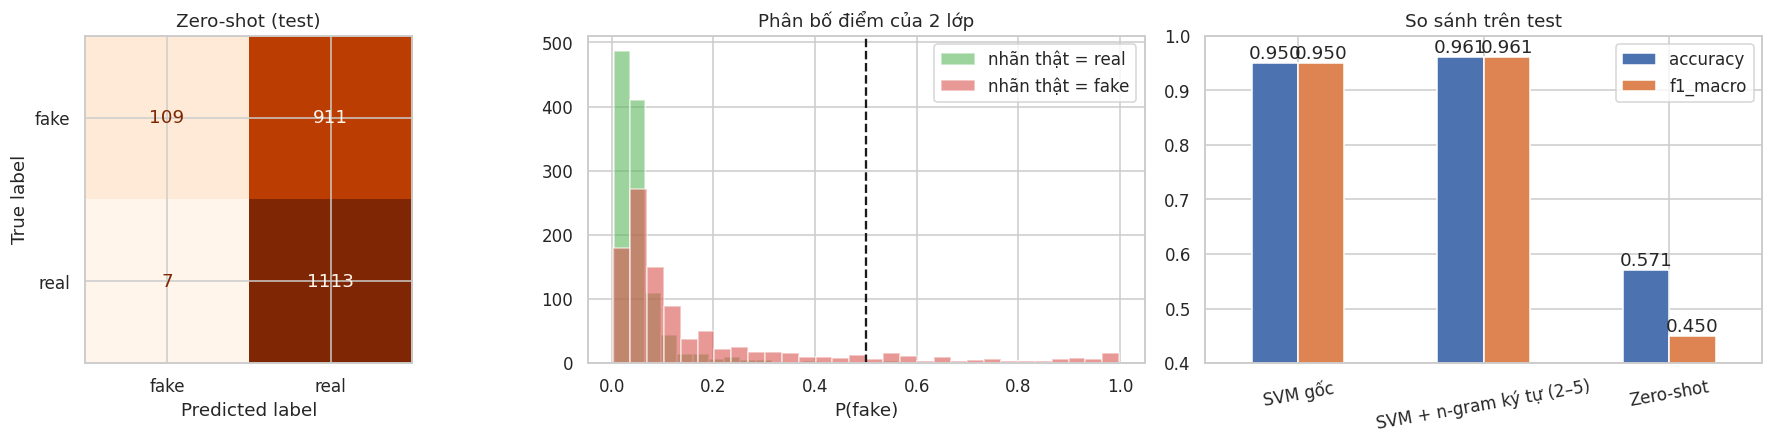

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ConfusionMatrixDisplay(confusion_matrix(test.label, zs_pred, labels=["fake", "real"]), display_labels=["fake", "real"]).plot(ax=ax[0], colorbar=False, cmap="Oranges")
ax[0].set_title("Zero-shot (test)")
for lb in ["real", "fake"]: ax[1].hist(pf[test.label == lb], bins=30, alpha=.6, color=COL[lb], label=f"nhãn thật = {lb}")
ax[1].axvline(0.5, ls="--", c="k"); ax[1].set_xlabel("P(fake)"); ax[1].set_title("Phân bố điểm của 2 lớp"); ax[1].legend()
comp = pd.DataFrame({"SVM gốc": {"accuracy": accuracy_score(test.label, test_pred), "f1_macro": f1m(test.label, test_pred)},
                     f"SVM {best_name}": {"accuracy": accuracy_score(test.label, imp_pred), "f1_macro": f1m(test.label, imp_pred)},
                     "Zero-shot": {k: zs_res[k] for k in ("accuracy", "f1_macro")}}).T
comp.plot(kind="bar", rot=10, ax=ax[2]); ax[2].set_ylim(0.4, 1); ax[2].set_title("So sánh trên test"); [ax[2].bar_label(c, fmt="%.3f") for c in ax[2].containers]
plt.tight_layout(); plt.show()

theo nhãn thật  fake          10.7
                real          99.4
theo độ dài     ngắn nhất     26.3
                ngắn          48.5
                dài           78.4
                dài nhất      76.8
theo có link    không link    38.4
                có link       74.8


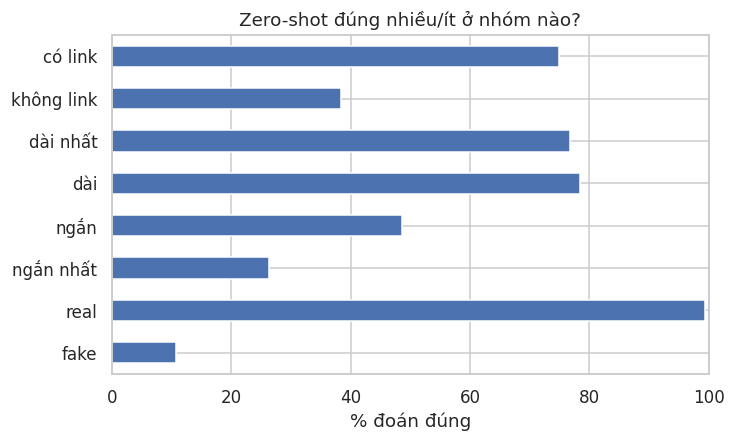


ĐÚNG và tự tin (chỗ zero-shot làm tốt):


,tweet,label,pf
190,Claim that Govt is providing money to bereaved families of COVID-19 victims is false,fake,0.998463
1065,We are proud to announce that India has realised PM @narendramodi's vision of conducting 10 lakh tests per day! This is a significant milestone in our fight against COVID-19. #IndiaFightsCorona @M...,real,0.004088
214,An even better piece of news: states reported fewer than 500 deaths. That hadn't happened since March. Yes there will probably be a larger number of deaths reported tomorrow as lagging weekend dat...,real,0.004094
983,Our daily update is published. We’ve now tracked 26.5 million tests up a whopping 584k from yesterday an all-time high. And for the first time the 7-day average has crossed the 500k minimum daily ...,real,0.004279


SAI mà tự tin (chỗ zero-shot chưa tốt):


,tweet,label,pf
2117,"Everyone knows that we're facing a real crisis from the coronavirus. But do you know how we got here and what we need to do next? Ron Klain, former White House Ebola Response Coordinator, breaks i...",fake,0.002578
1606,This is a headline every American should see: “Trump administration ended pandemic early-warning program to detect coronaviruses”\n\nDonald Trump’s shortsighted actions left our nation ill-prepare...,fake,0.003136
839,"Cure for Corona Virus. Good news, Wuhan’s corona virus can be cured by one bowl of freshly boiled garlic water. Old Chinese doctor has proven it’s efficacy. Many patients has also proven this to b...",fake,0.003238
1765,#Great news! Carona virus vaccine ready. Able to cure patient within 3 hours after injection. Hats off to US Scientists. Trump announced that Roche Medical Company will launch the vaccine next Sun...,fake,0.003696
1699,"""In a very real sense, (Oklahoma has) flattened the curve. ... The number of cases in Oklahoma ??"" it's declined precipitously.""",fake,0.006558


In [ ]:
# Phân tích: zero-shot tốt ở đâu, chưa tốt ở đâu?
te = add_feats(test); d = te.assign(pf=pf, pred=zs_pred); d["ok"] = d.pred == d.label
d["độ dài"] = pd.qcut(d.n_words, 4, labels=["ngắn nhất", "ngắn", "dài", "dài nhất"])
sl = pd.concat({"theo nhãn thật": d.groupby("label").ok.mean(), "theo độ dài": d.groupby("độ dài").ok.mean(),
                "theo có link": d.groupby("has_url").ok.mean().rename({False: "không link", True: "có link"})}) * 100
print(sl.round(1).to_string())
sl.droplevel(0).plot(kind="barh", figsize=(7, 4), color="#4c72b0"); plt.xlabel("% đoán đúng"); plt.xlim(0, 100); plt.title("Zero-shot đúng nhiều/ít ở nhóm nào?"); plt.show()

d["conf"] = np.abs(d.pf - 0.5) * 2
print("\nĐÚNG và tự tin (chỗ zero-shot làm tốt):"); display(d[d.ok].nlargest(4, "conf")[["tweet", "label", "pf"]])
print("SAI mà tự tin (chỗ zero-shot chưa tốt):");   display(d[~d.ok].nlargest(5, "conf")[["tweet", "label", "pf"]])

**Phân tích tốt / chưa tốt (viết lại theo số liệu của bạn):**
- **Chưa tốt chung:** so với baseline đã học trên chính dữ liệu này, zero-shot thấp hơn nhiều. Nhìn *ma trận nhầm lẫn* và `% bài bị đoán là fake`: nếu mô hình gần như không đoán fake thì nó thiên lệch về "real" (recall của fake rất thấp trong khi precision cao).
- **Có tín hiệu nhưng yếu:** AUC lớn hơn 0,5 nghĩa là điểm P(fake) vẫn xếp bài fake cao hơn bài real đôi chút; vấn đề chủ yếu là **ngưỡng và độ lệch**, không phải lỗi code.
- **Tốt ở đâu:** xem các bài *đúng và tự tin* và bảng theo nhóm: nhóm nào đúng nhiều hơn (thường là bài có dấu hiệu rõ ràng của tin đồn, hoặc bài chính thống viết đúng chuẩn).
- **Vì sao chưa tốt:** (1) NLI hỏi "bài này có hàm ý *đây là tin giả* không?" nhưng tin giả thường viết giọng khẳng định như tin thật, nên không gợi ra giả thuyết fake; (2) mô hình **không kiểm chứng sự thật** (không biết tỏi không chữa được COVID) còn nhãn dataset gán theo **nguồn**; (3) nó có xu hướng mặc định chọn "real news".
- **Ý nghĩa:** đây là lý do cần **fine-tune** để mô hình học phong cách và nguồn đặc thù của dataset.

## 9. Tổng hợp
| Phần | Nội dung | Mục |
|---|---|---|
| Bài toán + dataset + EDA | phân loại real/fake, 10.700 mẫu, nhãn cân bằng | 1–2 |
| Tiền xử lý | làm sạch, TF-IDF, bigram | 3 |
| Chẩn đoán overfit + chọn tham số | F1 train vs val theo `C` | 4.1 |
| Kết quả baseline + rò rỉ | F1 val/test, so đề, câu ngoài dataset | 4, 5 |
| Phân tích lỗi + khắc phục | nhóm dễ sai, câu sai, thử cải tiến | 6, 7 |
| Zero-shot | kết quả và phân tích tốt/chưa tốt | 8 |